# **Store Sales Forecasting Using Machine Learning**

## Goal
Build a simple machine learning model that forecasts daily store sales for Corporación Favorita, a large grocery retailer in Ecuador.

## Why
Accurate sales forecasts help a retailer plan stock, staff, and promotions.
Poor forecasts lead to empty shelves or wasted products.
This project also builds fundamental time series forecasting skills.

## Method
1. Explore and clean the data.
2. Aggregate sales to total daily sales.
3. Split the data by time: earlier dates for training, the last 30 days for validation.
4. Build 5 simple models: Naive, Seasonal Naive, Moving Average, Linear Regression, and Exponential Smoothing.
5. Compare the models with MAE, RMSE, and WAPE.
6. Select the model with the lowest validation error.

## Data
Source: Corporación Favorita sales data from Kaggle, stored in Google Drive.

| File | Content |
|---|---|
| `train.csv` | Daily sales by store and product family, plus promotions (main file) |
| `stores.csv` | Store details such as city and type |
| `oil.csv` | Daily oil price |
| `holidays_events.csv` | Holidays and events |
| `transactions.csv` | Daily transaction counts per store |

Target: `sales`
Main features: `date`, `store_nbr`, `family`, `onpromotion`

# 1. Setup

1. Mount Google Drive so Colab can read our files.
2. Import the libraries we need.
3. Load the data files and check that they loaded correctly.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

# Change this path if your folder sits somewhere else in Drive
data_path = '/content/drive/MyDrive/ML_Time_Series_Forecasting_Store_Sales'

print(os.listdir(data_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['holidays_events.csv', 'oil.csv', 'sample_submission.csv', 'stores.csv', 'test.csv', 'train.csv', 'transactions.csv']


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Make charts easier to read
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

In [ ]:
train = pd.read_csv(f'{data_path}/train.csv', parse_dates=['date'])
stores = pd.read_csv(f'{data_path}/stores.csv')
oil = pd.read_csv(f'{data_path}/oil.csv', parse_dates=['date'])
holidays = pd.read_csv(f'{data_path}/holidays_events.csv', parse_dates=['date'])
transactions = pd.read_csv(f'{data_path}/transactions.csv', parse_dates=['date'])

# 2. Load Data

In [ ]:
files = {
    'train': train,
    'stores': stores,
    'oil': oil,
    'holidays': holidays,
    'transactions': transactions
}

for name, df in files.items():
    print(f'{name}: {df.shape[0]} rows, {df.shape[1]} columns')
    print('Columns:', list(df.columns))
    print()

train: 3000888 rows, 6 columns
Columns: ['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion']

stores: 54 rows, 5 columns
Columns: ['store_nbr', 'city', 'state', 'type', 'cluster']

oil: 1218 rows, 2 columns
Columns: ['date', 'dcoilwtico']

holidays: 350 rows, 6 columns
Columns: ['date', 'type', 'locale', 'locale_name', 'description', 'transferred']

transactions: 83488 rows, 3 columns
Columns: ['date', 'store_nbr', 'transactions']



In [ ]:
train.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [ ]:
memory_mb = train.memory_usage(deep=True).sum() / 1024**2
print(f'train.csv uses about {memory_mb:.1f} MB of memory')

train.csv uses about 285.5 MB of memory


**What we did**

- We mounted Google Drive and listed the files before loading them.
- We loaded 5 files. We skipped `test.csv` because this project does not need it.
- We checked the shape and columns of each file.
- We checked the memory use of `train.csv` to make sure Colab can handle it.

# 3. Data Inspection

Before we change anything, we check the structure of each file.
We look at data types, summary statistics, the date range, and missing dates.

In [ ]:
# Data types and missing values in train

train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int64         
 1   date         datetime64[ns]
 2   store_nbr    int64         
 3   family       object        
 4   sales        float64       
 5   onpromotion  int64         
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 137.4+ MB


In [ ]:
# Summary statistics for train

train[['sales', 'onpromotion']].describe()

,sales,onpromotion
count,3.000888e+06,3.000888e+06
mean,3.577757e+02,2.602770e+00
std,1.101998e+03,1.221888e+01
min,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00
50%,1.100000e+01,0.000000e+00
75%,1.958473e+02,0.000000e+00
max,1.247170e+05,7.410000e+02


In [ ]:
# Date range and number of unique dates

print('First date:', train['date'].min())
print('Last date:', train['date'].max())
print('Unique dates:', train['date'].nunique())
print('Stores:', train['store_nbr'].nunique())
print('Product families:', train['family'].nunique())

First date: 2013-01-01 00:00:00
Last date: 2017-08-15 00:00:00
Unique dates: 1684
Stores: 54
Product families: 33


In [ ]:
# Check for missing dates

full_range = pd.date_range(train['date'].min(), train['date'].max(), freq='D')
missing_dates = full_range.difference(train['date'].unique())

print('Days in full calendar:', len(full_range))
print('Days in train:', train['date'].nunique())
print('Missing dates:', list(missing_dates))

Days in full calendar: 1688
Days in train: 1684
Missing dates: [Timestamp('2013-12-25 00:00:00'), Timestamp('2014-12-25 00:00:00'), Timestamp('2015-12-25 00:00:00'), Timestamp('2016-12-25 00:00:00')]


A daily time series should have one row per day. We compare the dates we have with a full calendar.

In [ ]:
# Check the other files

print('--- stores ---')
print(stores.head())
print()
print('--- oil ---')
print(oil.head())
print('Missing oil prices:', oil['dcoilwtico'].isna().sum())
print()
print('--- holidays ---')
print(holidays.head())
print()
print('--- transactions ---')
print(transactions.head())

--- stores ---
   store_nbr           city                           state type  cluster
0          1          Quito                       Pichincha    D       13
1          2          Quito                       Pichincha    D       13
2          3          Quito                       Pichincha    D        8
3          4          Quito                       Pichincha    D        9
4          5  Santo Domingo  Santo Domingo de los Tsachilas    D        4

--- oil ---
        date  dcoilwtico
0 2013-01-01         NaN
1 2013-01-02       93.14
2 2013-01-03       92.97
3 2013-01-04       93.12
4 2013-01-07       93.20
Missing oil prices: 43

--- holidays ---
        date     type    locale locale_name                    description  \
0 2012-03-02  Holiday     Local       Manta             Fundacion de Manta   
1 2012-04-01  Holiday  Regional    Cotopaxi  Provincializacion de Cotopaxi   
2 2012-04-12  Holiday     Local      Cuenca            Fundacion de Cuenca   
3 2012-04-14  Holiday    

In [ ]:
# Check that join keys are unique

print('Duplicate store_nbr in stores:', stores['store_nbr'].duplicated().sum())
print('Duplicate dates in oil:', oil['date'].duplicated().sum())
print('Duplicate (date, store) in transactions:',
      transactions.duplicated(subset=['date', 'store_nbr']).sum())
print('Duplicate dates in holidays:', holidays['date'].duplicated().sum())

Duplicate store_nbr in stores: 0
Duplicate dates in oil: 0
Duplicate (date, store) in transactions: 0
Duplicate dates in holidays: 38


We must know this before any merge. A non-unique key would create extra rows.

Holidays can have repeated dates, because a national and a local event can fall on the same day.

### What we check

- **Data types:** `date` should be datetime, `sales` should be float.
- **Date range:** we need to know how much history we have.
- **Missing dates:** gaps would break weekly patterns and lag features.
- **Join keys:** we confirm keys are unique before merging files.

## **Outputs**

1. Data types are correct. `date` is datetime and `sales` is float.
2. History: 2013-01-01 to 2017-08-15, which is 1,684 unique dates, 54 stores, and 33 product families.
3. Missing dates: only 4 days are missing, and all are December 25 (2013 to 2016). Christmas Day is a store closure, so these are not data errors. We do not fill them with zero.
4. Sales: the median is 11 and the 75th percentile is about 196, but the max is 124,717. The data is heavily skewed. The minimum is 0, so there are no negative sales in this file.
5. Promotions: the median is 0, so most rows have no promotion.
6. Oil: 43 missing prices. Oil only matters if we use it as a feature, so we handle it in the EDA step.
7. Join keys: `stores`, `oil`, and `transactions` are unique. `holidays` has 38 repeated dates, which we handle later if we use holidays.

# Data Cleaning and Processing

We check missing values, duplicates, and odd sales values.
We explain each decision before we change any data.

In [ ]:
# Missing values and duplicates in train

print('Missing values in train:')
print(train.isna().sum())
print()
print('Duplicate rows:', train.duplicated().sum())
print('Duplicate (date, store, family):',
      train.duplicated(subset=['date', 'store_nbr', 'family']).sum())

Missing values in train:
id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

Duplicate rows: 0
Duplicate (date, store, family): 0


In [ ]:
# Zero and negative sales

total_rows = len(train)
zero_rows = (train['sales'] == 0).sum()
negative_rows = (train['sales'] < 0).sum()

print(f'Zero sales rows: {zero_rows} ({zero_rows / total_rows:.1%})')
print(f'Negative sales rows: {negative_rows}')

Zero sales rows: 939130 (31.3%)
Negative sales rows: 0


In [ ]:
# Are zeros real? Check zero sales by day for the first week

daily_check = train.groupby('date').agg(
    total_sales=('sales', 'sum'),
    stores_with_sales=('store_nbr', lambda s: s[train.loc[s.index, 'sales'] > 0].nunique())
)

print(daily_check.head(10))

              total_sales  stores_with_sales
date                                        
2013-01-01    2511.618999                  1
2013-01-02  496092.417944                 46
2013-01-03  361461.231124                 46
2013-01-04  354459.677093                 46
2013-01-05  477350.121229                 46
2013-01-06  519695.401088                 46
2013-01-07  336122.801066                 46
2013-01-08  318347.777981                 46
2013-01-09  302530.809018                 46
2013-01-10  258982.003049                 46


Zeros can mean no sales, or a store that had not opened yet. We check by looking at the number of stores with any sales each day.

In [ ]:
# Find stores that opened late

store_sales = train.groupby(['store_nbr', 'date'])['sales'].sum().reset_index()
first_sale = store_sales[store_sales['sales'] > 0].groupby('store_nbr')['date'].min()

print(first_sale.sort_values().tail(15))

store_nbr
15   2013-01-02
16   2013-01-02
17   2013-01-02
18   2013-01-02
19   2013-01-02
14   2013-01-02
54   2013-01-02
36   2013-05-09
53   2014-05-29
20   2015-02-13
29   2015-03-20
21   2015-07-24
42   2015-08-21
22   2015-10-09
52   2017-04-20
Name: date, dtype: datetime64[ns]


In [ ]:
# Aggregate to total daily sales and check the result

daily = train.groupby('date').agg(
    sales=('sales', 'sum'),
    onpromotion=('onpromotion', 'sum')
).reset_index()

daily = daily.sort_values('date').reset_index(drop=True)

print(daily.shape)
print(daily.head())
print()
print('Days with zero total sales:', (daily['sales'] == 0).sum())

(1684, 3)
        date          sales  onpromotion
0 2013-01-01    2511.618999            0
1 2013-01-02  496092.417944            0
2 2013-01-03  361461.231124            0
3 2013-01-04  354459.677093            0
4 2013-01-05  477350.121229            0

Days with zero total sales: 0


This is the series we forecast. We aggregate now so the cleaning decisions below are based on it.

In [ ]:
# Check the daily series for odd values

print(daily['sales'].describe())
print()
print('Lowest 5 days:')
print(daily.nsmallest(5, 'sales')[['date', 'sales']])

count    1.684000e+03
mean     6.375564e+05
std      2.344102e+05
min      2.511619e+03
25%      4.427115e+05
50%      6.321889e+05
75%      7.859455e+05
max      1.463084e+06
Name: sales, dtype: float64

Lowest 5 days:
           date         sales
0    2013-01-01   2511.618999
364  2014-01-01   8602.065404
1457 2017-01-01  12082.500997
728  2015-01-01  12773.616980
1092 2016-01-01  16433.394000


- **Missing dates:** the 4 missing dates are December 25. Stores are closed, so we do not fill them with zero.
  We keep them out of the series. For lag-based models we will use a regular daily index, so we decide how to handle them in Step 7.
- **Zero sales:** we decide after we see how many zeros exist and whether they come from stores that had not opened yet.
- **Negative sales:** none exist, so no action is needed.
- **Duplicates:** we remove them only if the check finds any.
- **Aggregation:** we sum sales across all stores and families to get one row per date.

**Cleaning Decisions**

- **Missing values and duplicates:** none found. No action needed.
- **Negative sales:** none found. No action needed.
- **Zero sales (31.3% of rows):** kept. They are real "nothing sold" values, and many come from product families that sell rarely or from stores that had not opened yet.
- **2013-01-01:** removed from the modeling series. Only 1 of 54 stores reported sales, so it does not show normal sales.
- **January 1 of other years:** kept. They are real low-sales days caused by the holiday.
- **Missing dates (December 25, 4 years):** stores were closed. We do not treat them as zero sales. We handle them in Step 7 so lag-based models keep a regular daily calendar.
- **Original data:** `train` stays unchanged. All changes go into the `daily` table.

In [ ]:
# Apply the cleaning decisions

# Remove 2013-01-01 from the daily series
daily = daily[daily['date'] > '2013-01-01'].reset_index(drop=True)

print('Daily rows after cleaning:', daily.shape[0])
print('First date:', daily['date'].min())
print('Last date:', daily['date'].max())

Daily rows after cleaning: 1683
First date: 2013-01-02 00:00:00
Last date: 2017-08-15 00:00:00


In [ ]:
# Quick check of the cleaned series

daily.head()

,date,sales,onpromotion
0,2013-01-02,496092.417944,0
1,2013-01-03,361461.231124,0
2,2013-01-04,354459.677093,0
3,2013-01-05,477350.121229,0
4,2013-01-06,519695.401088,0


Note that promotions are 0 for the first rows. The promotion data may not start until later, so we check this in EDA before using it as a feature.

# 5. EDA

We look at patterns that will guide our model choice.

We check the trend, the weekly pattern, the yearly pattern, the sales distribution, promotions, and the top stores and families.

**Sales over time**

In [ ]:
# Add calendar columns

daily['weekday'] = daily['date'].dt.day_name()
daily['month'] = daily['date'].dt.month
daily['year'] = daily['date'].dt.year

daily.head()

,date,sales,onpromotion,weekday,month,year
0,2013-01-02,496092.417944,0,Wednesday,1,2013
1,2013-01-03,361461.231124,0,Thursday,1,2013
2,2013-01-04,354459.677093,0,Friday,1,2013
3,2013-01-05,477350.121229,0,Saturday,1,2013
4,2013-01-06,519695.401088,0,Sunday,1,2013


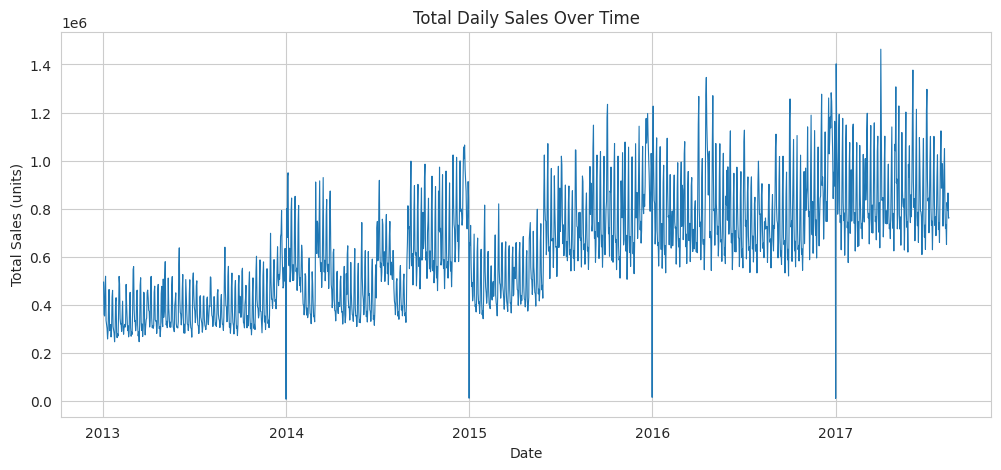

In [ ]:
# Line chart of total daily sales

plt.figure()
plt.plot(daily['date'], daily['sales'], linewidth=0.8)
plt.title('Total Daily Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Total Sales (units)')
plt.show()

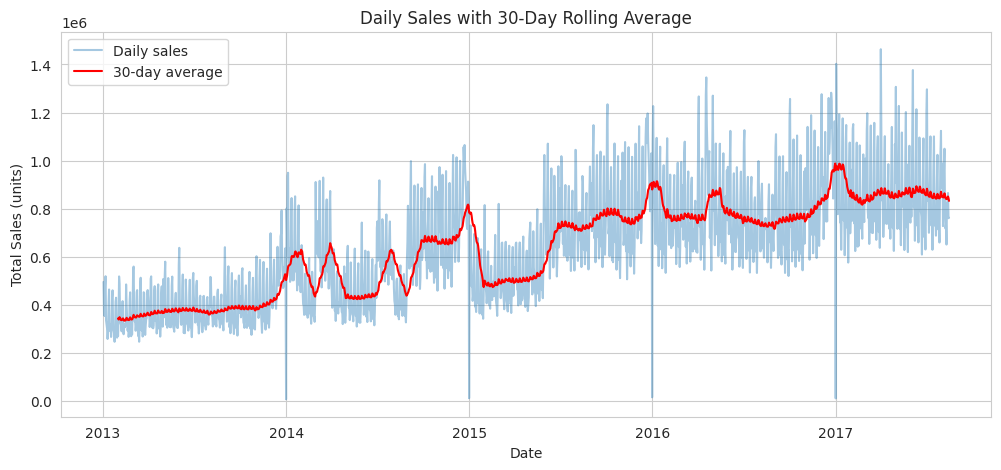

In [ ]:
# Add a 30-day rolling average to see the trend

daily['rolling_30'] = daily['sales'].rolling(30).mean()

plt.figure()
plt.plot(daily['date'], daily['sales'], alpha=0.4, label='Daily sales')
plt.plot(daily['date'], daily['rolling_30'], color='red', label='30-day average')
plt.title('Daily Sales with 30-Day Rolling Average')
plt.xlabel('Date')
plt.ylabel('Total Sales (units)')
plt.legend()
plt.show()

A rolling average smooths out the daily noise.

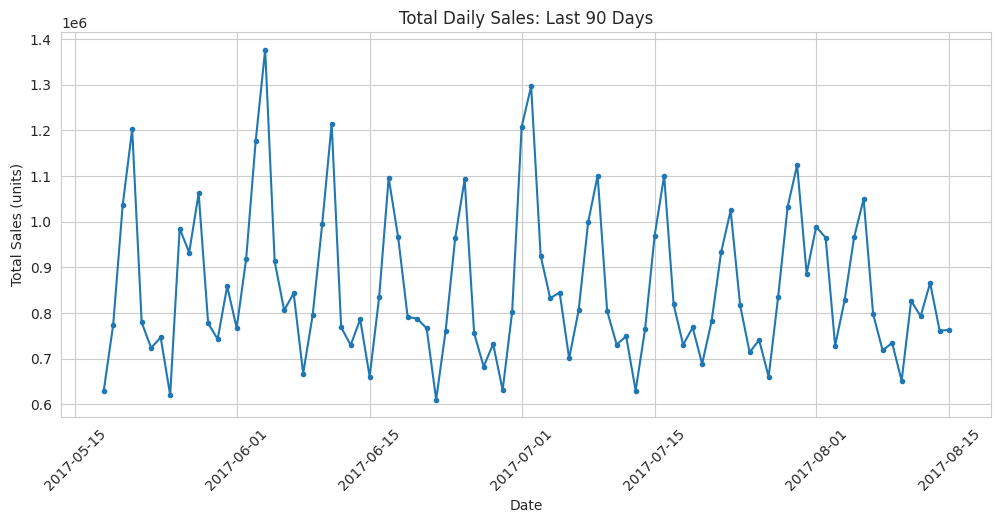

In [ ]:
# Zoom into the last 90 days

last_90 = daily.tail(90)

plt.figure()
plt.plot(last_90['date'], last_90['sales'], marker='o', markersize=3)
plt.title('Total Daily Sales: Last 90 Days')
plt.xlabel('Date')
plt.ylabel('Total Sales (units)')
plt.xticks(rotation=45)
plt.show()

This is the period closest to our forecast, so we want to see it clearly.

**Weekly and yearly patterns**

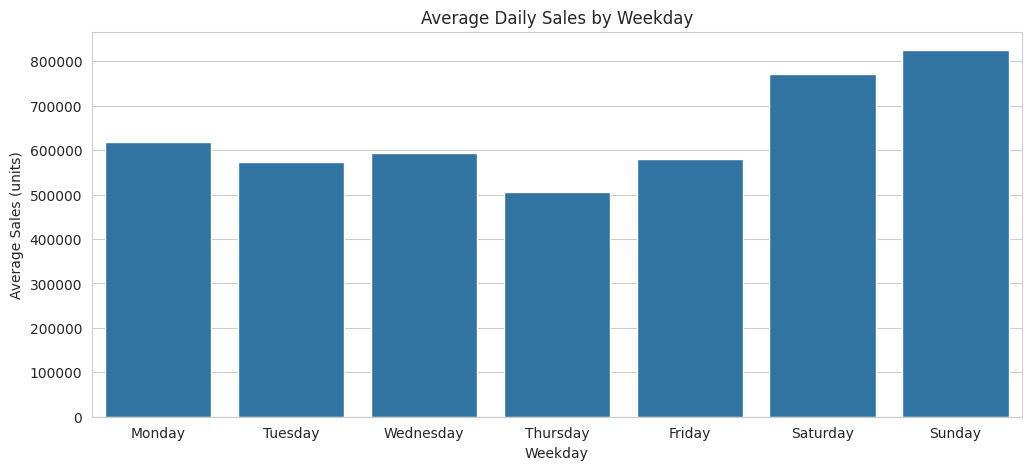

weekday
Monday       617543.0
Tuesday      572281.0
Wednesday    593245.0
Thursday     505269.0
Friday       579574.0
Saturday     772206.0
Sunday       825218.0
Name: sales, dtype: float64


In [ ]:
# Average sales by weekday

weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
                 'Friday', 'Saturday', 'Sunday']

weekday_avg = daily.groupby('weekday')['sales'].mean().reindex(weekday_order)

plt.figure()
sns.barplot(x=weekday_avg.index, y=weekday_avg.values)
plt.title('Average Daily Sales by Weekday')
plt.xlabel('Weekday')
plt.ylabel('Average Sales (units)')
plt.show()

print(weekday_avg.round(0))

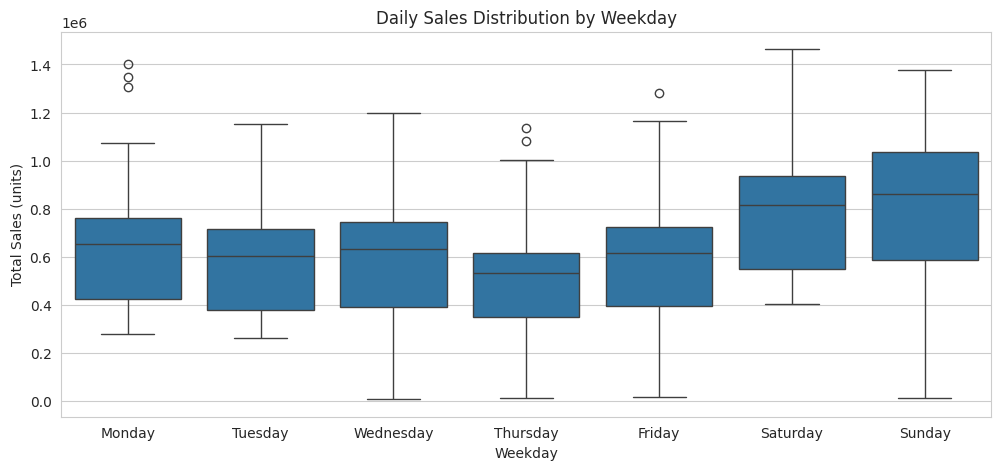

In [ ]:
# Box plot of sales by weekday

plt.figure()
sns.boxplot(data=daily, x='weekday', y='sales', order=weekday_order)
plt.title('Daily Sales Distribution by Weekday')
plt.xlabel('Weekday')
plt.ylabel('Total Sales (units)')
plt.show()

The box plot shows the spread, not only the average.

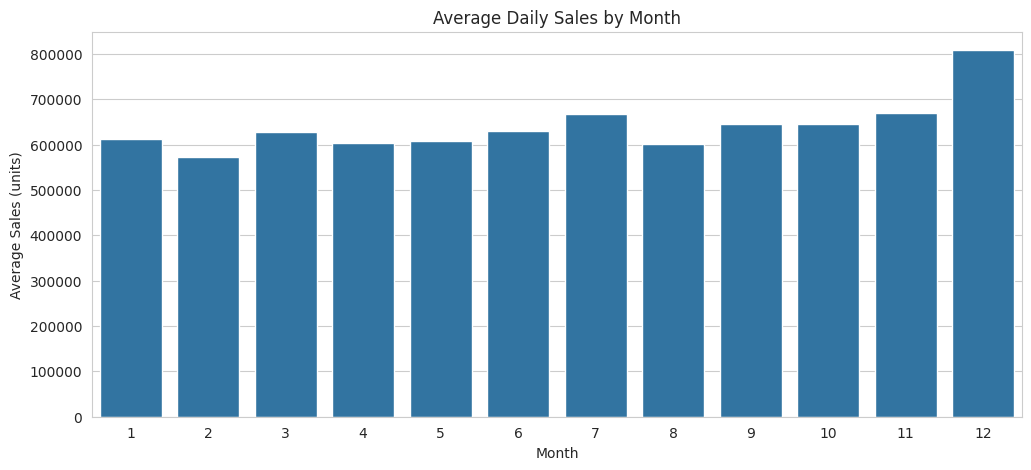

In [ ]:
# Average sales by month

month_avg = daily.groupby('month')['sales'].mean()

plt.figure()
sns.barplot(x=month_avg.index, y=month_avg.values)
plt.title('Average Daily Sales by Month')
plt.xlabel('Month')
plt.ylabel('Average Sales (units)')
plt.show()

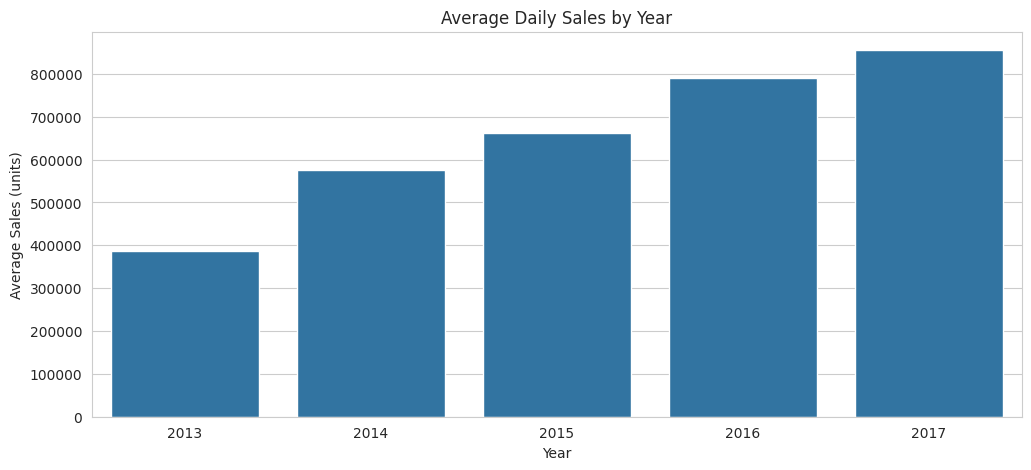

year
2013    386822.0
2014    575479.0
2015    661759.0
2016    790834.0
2017    855582.0
Name: sales, dtype: float64


In [ ]:
# Average sales by year

year_avg = daily.groupby('year')['sales'].mean()

plt.figure()
sns.barplot(x=year_avg.index, y=year_avg.values)
plt.title('Average Daily Sales by Year')
plt.xlabel('Year')
plt.ylabel('Average Sales (units)')
plt.show()

print(year_avg.round(0))

2017 has only 7.5 months of data, so we compare average daily sales, not totals.

**Sales distribution**

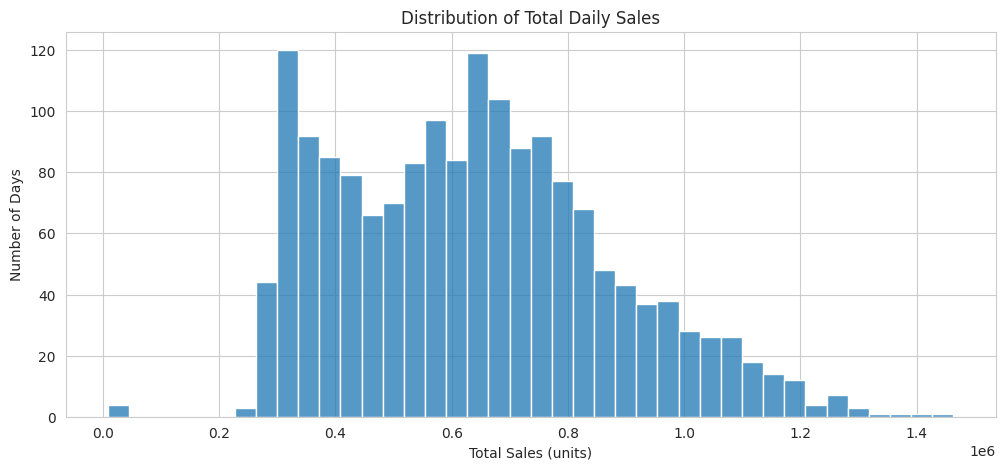

In [ ]:
# Histogram of daily sales

plt.figure()
sns.histplot(daily['sales'], bins=40)
plt.title('Distribution of Total Daily Sales')
plt.xlabel('Total Sales (units)')
plt.ylabel('Number of Days')
plt.show()

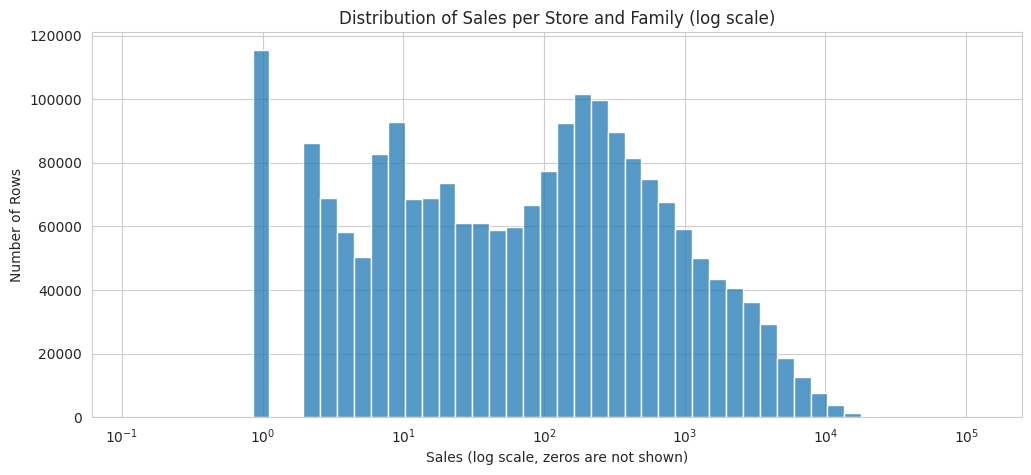

In [ ]:
# Histogram of row-level sales

plt.figure()
sns.histplot(train['sales'], bins=50, log_scale=(True, False))
plt.title('Distribution of Sales per Store and Family (log scale)')
plt.xlabel('Sales (log scale, zeros are not shown)')
plt.ylabel('Number of Rows')
plt.show()

At row level, 31% of values are zero. We use a log scale on the x-axis so we can see the shape.

**Promotions**

First date with promotions: 2014-04-01 00:00:00


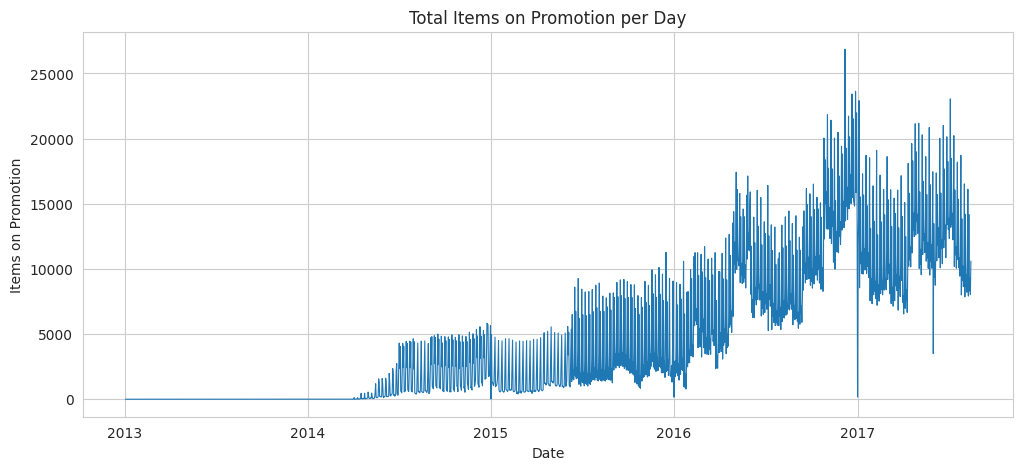

In [ ]:
# When do promotions start?

first_promo = daily[daily['onpromotion'] > 0]['date'].min()
print('First date with promotions:', first_promo)

plt.figure()
plt.plot(daily['date'], daily['onpromotion'], linewidth=0.8)
plt.title('Total Items on Promotion per Day')
plt.xlabel('Date')
plt.ylabel('Items on Promotion')
plt.show()

We saw zero promotions in the first rows. We check the first date with any promotion.

promo_level
Low            575165.0
Medium-Low     684834.0
Medium-High    771121.0
High           836952.0
Name: sales, dtype: float64


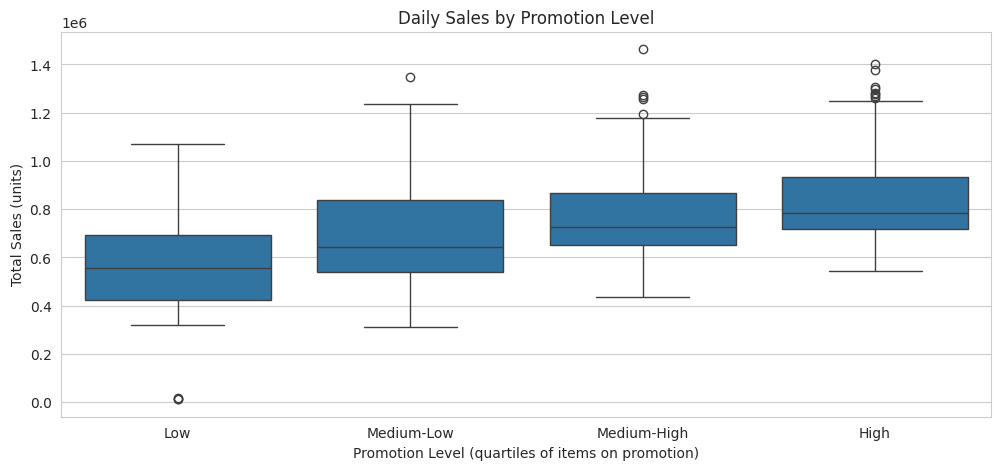

In [ ]:
# Sales on promotion days vs non-promotion days

promo_period = daily[daily['date'] >= first_promo].copy()

promo_period['promo_level'] = pd.qcut(
    promo_period['onpromotion'], q=4,
    labels=['Low', 'Medium-Low', 'Medium-High', 'High']
)

print(promo_period.groupby('promo_level', observed=True)['sales'].mean().round(0))

plt.figure()
sns.boxplot(data=promo_period, x='promo_level', y='sales')
plt.title('Daily Sales by Promotion Level')
plt.xlabel('Promotion Level (quartiles of items on promotion)')
plt.ylabel('Total Sales (units)')
plt.show()

We only compare days after promotions began. Before that date, “no promotion” means “not recorded”, not “no promotion”.

In [ ]:
# Correlation between sales and promotions

corr = promo_period[['sales', 'onpromotion']].corr()
print(corr.round(3))

             sales  onpromotion
sales        1.000        0.432
onpromotion  0.432        1.000


Correlation shows that two things move together. It does not prove that promotions cause higher sales. Both may rise over time.

**Stores and product families**

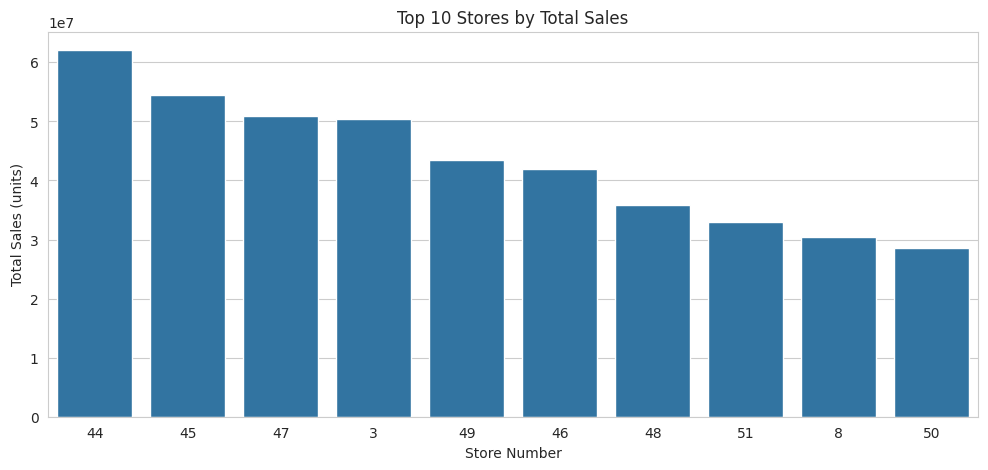

In [ ]:
# Top 10 stores by total sales

top_stores = (train.groupby('store_nbr')['sales'].sum()
              .sort_values(ascending=False).head(10))

plt.figure()
sns.barplot(x=top_stores.index.astype(str), y=top_stores.values)
plt.title('Top 10 Stores by Total Sales')
plt.xlabel('Store Number')
plt.ylabel('Total Sales (units)')
plt.show()

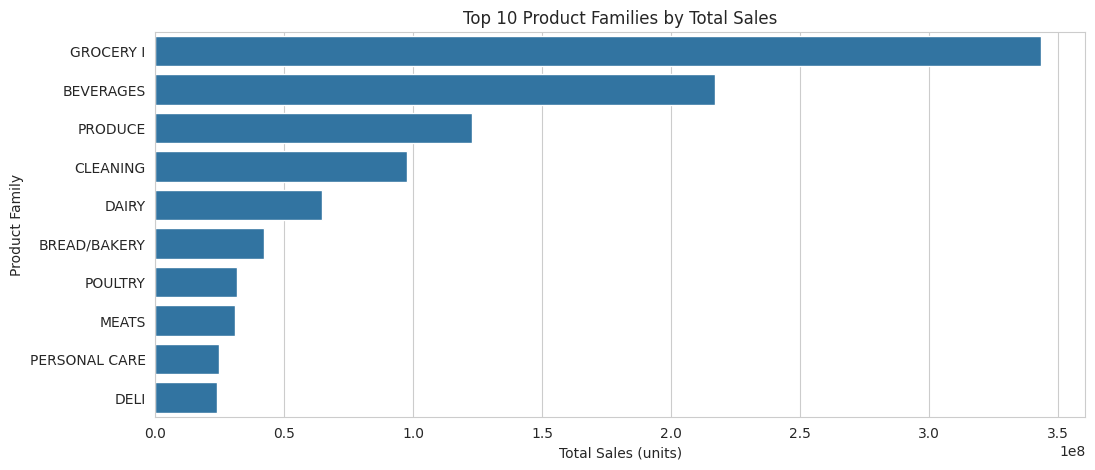

In [ ]:
# Top 10 product families by total sales

top_families = (train.groupby('family')['sales'].sum()
                .sort_values(ascending=False).head(10))

plt.figure()
sns.barplot(x=top_families.values, y=top_families.index)
plt.title('Top 10 Product Families by Total Sales')
plt.xlabel('Total Sales (units)')
plt.ylabel('Product Family')
plt.show()

Rows before join: 3000888 | after join: 3000888


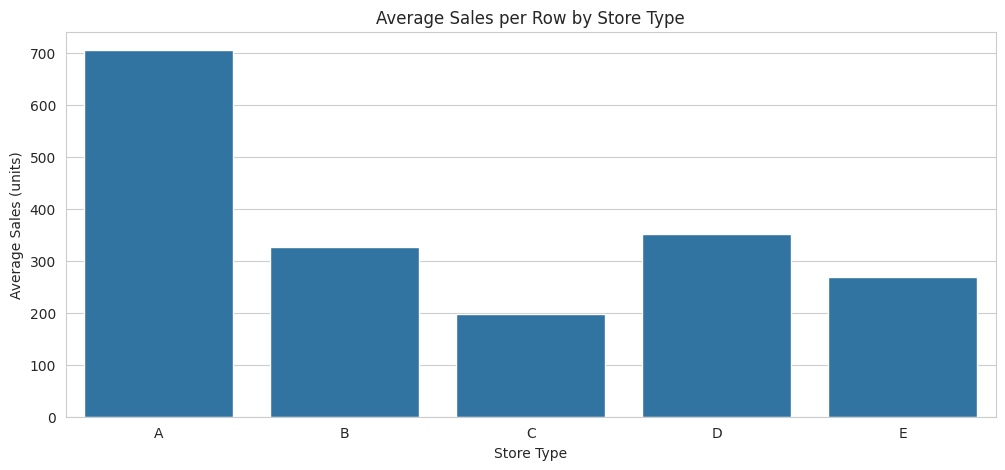

In [ ]:
# Average sales by store type

rows_before = len(train)
train_stores = train.merge(stores[['store_nbr', 'type']], on='store_nbr', how='left')
print('Rows before join:', rows_before, '| after join:', len(train_stores))

type_sales = train_stores.groupby('type')['sales'].mean()

plt.figure()
sns.barplot(x=type_sales.index, y=type_sales.values)
plt.title('Average Sales per Row by Store Type')
plt.xlabel('Store Type')
plt.ylabel('Average Sales (units)')
plt.show()

del train_stores

This uses stores.csv to see if store type matters. We join on store_nbr, which is unique, and we check the row count.

**Oil and transactions**

Rows after join: 1683
Missing oil values: 481
            sales  dcoilwtico
sales        1.00       -0.69
dcoilwtico  -0.69        1.00


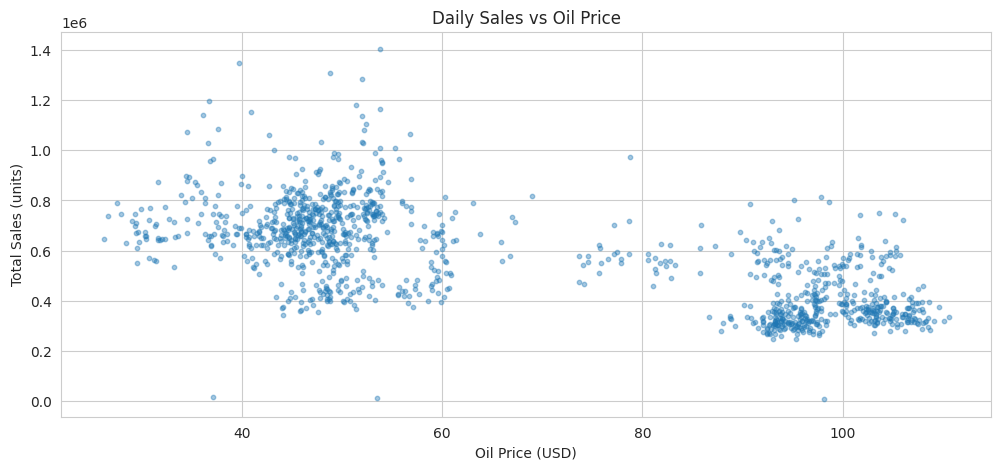

In [ ]:
oil_clean = oil.copy()
oil_clean['dcoilwtico'] = oil_clean['dcoilwtico'].ffill().bfill()

daily_oil = daily.merge(oil_clean, on='date', how='left')
print('Rows after join:', len(daily_oil))
print('Missing oil values:', daily_oil['dcoilwtico'].isna().sum())

print(daily_oil[['sales', 'dcoilwtico']].corr().round(3))

plt.figure()
plt.scatter(daily_oil['dcoilwtico'], daily_oil['sales'], alpha=0.4, s=10)
plt.title('Daily Sales vs Oil Price')
plt.xlabel('Oil Price (USD)')
plt.ylabel('Total Sales (units)')
plt.show()

Oil has 43 missing prices. We fill them with the previous known price (forward fill), because oil prices change slowly. We use it only for this check.

In [ ]:
# Total transactions vs total sales

daily_tx = transactions.groupby('date')['transactions'].sum().reset_index()
daily_tx = daily.merge(daily_tx, on='date', how='left')

print('Missing transaction values:', daily_tx['transactions'].isna().sum())
print(daily_tx[['sales', 'transactions']].corr().round(3))

Missing transaction values: 2
              sales  transactions
sales         1.000         0.676
transactions  0.676         1.000


### What we check

- **Trend:** does average daily sales rise over time?
- **Weekly pattern:** do some weekdays sell much more than others?
- **Yearly pattern:** do some months sell more?
- **Promotions:** do high-promotion days show higher sales, and when do promotions start?
- **Stores and families:** which ones drive total sales?
- **Oil and transactions:** do they move with sales?

Correction 1: The Oil Check Was Wrong

481 missing oil values after the join.

1. `oil.csv` has only weekdays (1,218 rows), so weekends are not in the file.
2. I filled the gaps inside the oil file, but the weekend dates did not exist there yet.
3. The merge then created 481 new empty rows, and `.corr()` skipped them.
4. So the -0.69 correlation used only 1,202 weekdays. We do not trust it.

In [ ]:
# merge first, then fill on the daily calendar.

daily_oil = daily.merge(oil, on='date', how='left')
daily_oil['dcoilwtico'] = daily_oil['dcoilwtico'].ffill().bfill()

print('Rows:', len(daily_oil))
print('Missing oil values:', daily_oil['dcoilwtico'].isna().sum())
print(daily_oil[['sales', 'dcoilwtico']].corr().round(3))

Rows: 1683
Missing oil values: 0
            sales  dcoilwtico
sales       1.000      -0.627
dcoilwtico -0.627       1.000


Correction 2: 2 missing transaction values

Two days have no transactions. We check which ones.

In [ ]:
daily_tx = daily.merge(
    transactions.groupby('date')['transactions'].sum().reset_index(),
    on='date', how='left')
print(daily_tx[daily_tx['transactions'].isna()][['date']])

           date
1091 2016-01-01
1093 2016-01-03


New check: sales level shifts in 2014 and early 2015

In your 30-day average chart, the level jumps between about 0.4M and 0.65M during 2014 and early 2015. That is more than a smooth trend. A likely cause is that some stores stopped reporting for periods. We test this by counting stores with sales on each day.

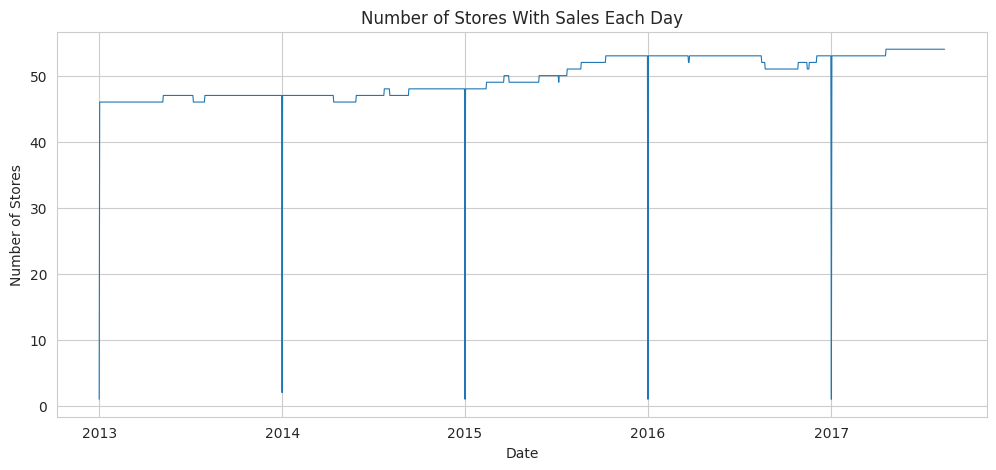

count    1684.000000
mean       49.647268
std         3.899242
min         1.000000
25%        47.000000
50%        49.000000
75%        53.000000
max        54.000000
Name: store_nbr, dtype: float64


In [ ]:
active_stores = (store_sales[store_sales['sales'] > 0]
                 .groupby('date')['store_nbr'].nunique())

plt.figure()
plt.plot(active_stores.index, active_stores.values, linewidth=0.8)
plt.title('Number of Stores With Sales Each Day')
plt.xlabel('Date')
plt.ylabel('Number of Stores')
plt.show()

print(active_stores.describe())

## Key EDA Findings

All findings below come from our charts and printed outputs.

## Main insights

1. **Strong upward trend.** Average daily sales rose from about 387,000 units in 2013 to about 856,000 in 2017. That is about 2.2 times higher.
   A model needs a trend component or recent data to capture this.

2. **Strong weekly pattern.** Sunday is the highest day (about 825,000) and Saturday is second (about 772,000).
   Thursday is the lowest (about 505,000). Sunday sells about 63% more than Thursday.
   This tells us to use weekday features and a 7-day seasonal model.

3. **December is the highest month.** Average daily sales in December are about 810,000. Other months sit between about 570,000 and 670,000.
   This value mixes the trend and the season, because 2017 has no December data.

4. **January 1 is a near-zero day every year.** These days appear as sharp drops in the line chart and as a small bar near zero in the histogram.
   Our validation period (July and August 2017) has no such day. The number of active stores rose from 46 to 54 over the period, which explains part of the sales growth.

5. **Promotions are recorded only from 2014-04-01.** Before that date, a value of 0 means "not recorded", not "no promotion".
   From that date, sales rise with promotion level: the average is about 575,000 in the Low group and about 837,000 in the High group.
   The correlation is 0.43. Promotions and sales both grow over time, so this does not prove that promotions cause the increase.

6. **Transactions move with sales (correlation 0.68), but we cannot use them.** We would not know future transactions when we forecast.

7. **Oil price is not used.** The scatter plot shows two separate clusters that match two time periods:
   high oil with low sales in 2013 and 2014, and low oil with higher sales later.
   The corrected correlation is -0.63, but both series trend over time, so we do not use oil.

8. **Stores and families.** Stores 44, 45, 47, and 3 have the highest total sales.
   GROCERY I, BEVERAGES, and PRODUCE are the top 3 families.
   Store type A has the highest average sales per row.
   We forecast total sales, so these results explain the data but do not change the model.

## What this means for modeling

- Use a **time index** for the trend and **weekday dummies** for the weekly pattern.
- Use **onpromotion** only for dates on or after 2014-04-01.
- The last 30 days (our validation period) show a stable level of about 0.85 million units with a clear weekly cycle.

# 7. Forecasting Scope and Target

## Target
Total daily sales across all stores and product families (`sales` in the `daily` table).

## Decisions
1. **Training start date.** Promotions are recorded only from 2014-04-01. We keep all dates from 2013-01-02 so the model sees the full trend.
   We use `onpromotion` only as a feature if it helps, and we test this in Step 10.
2. **Christmas Day.** Stores were closed on Dec 25 of 2013 to 2016. We build a regular daily calendar and fill these 4 days
   with the average of the day before and the day after. We add a flag column so we can see them.
3. **Calendar features.** Time index, weekday, and month. We create them from the date only, so they are known in advance.
4. **Forecast horizon.** 30 days, which is our validation period.

In [ ]:
# Build a regular daily calendar

# Keep only the columns we need
model_df = daily[['date', 'sales', 'onpromotion']].copy()

# Create a full daily calendar and join our data to it
calendar = pd.DataFrame({'date': pd.date_range(model_df['date'].min(),
                                               model_df['date'].max(), freq='D')})
model_df = calendar.merge(model_df, on='date', how='left')

# Flag the rows that were missing before we fill them
model_df['filled'] = model_df['sales'].isna().astype(int)

print('Rows:', len(model_df))
print('Filled rows:', model_df['filled'].sum())
print(model_df[model_df['filled'] == 1]['date'].tolist())

Rows: 1687
Filled rows: 4
[Timestamp('2013-12-25 00:00:00'), Timestamp('2014-12-25 00:00:00'), Timestamp('2015-12-25 00:00:00'), Timestamp('2016-12-25 00:00:00')]


In [ ]:
# Fill the 4 Christmas days

model_df['sales'] = model_df['sales'].interpolate()
model_df['onpromotion'] = model_df['onpromotion'].interpolate()

print('Missing sales after fill:', model_df['sales'].isna().sum())
print(model_df[model_df['filled'] == 1])

Missing sales after fill: 0
           date         sales  onpromotion  filled
357  2013-12-25  5.456972e+05          0.0       1
722  2014-12-25  9.190407e+05       5771.0       1
1087 2015-12-25  1.015203e+06       1781.5       1
1453 2016-12-25  1.139804e+06      15034.0       1


interpolate() fills each gap with a straight line between the day before and the day after. With a single missing day, this equals the average of the two neighbors.

In [ ]:
# Add calendar features

model_df['time_index'] = np.arange(len(model_df))
model_df['weekday'] = model_df['date'].dt.dayofweek   # 0 = Monday
model_df['month'] = model_df['date'].dt.month

model_df.head()

,date,sales,onpromotion,filled,time_index,weekday,month
0,2013-01-02,496092.417944,0.0,0,0,2,1
1,2013-01-03,361461.231124,0.0,0,1,3,1
2,2013-01-04,354459.677093,0.0,0,2,4,1
3,2013-01-05,477350.121229,0.0,0,3,5,1
4,2013-01-06,519695.401088,0.0,0,4,6,1


In [ ]:
# Check the final table

print(model_df.shape)
print(model_df.dtypes)
print()
print('First date:', model_df['date'].min())
print('Last date:', model_df['date'].max())
print('Days in calendar:', len(model_df))

(1687, 7)
date           datetime64[ns]
sales                 float64
onpromotion           float64
filled                  int64
time_index              int64
weekday                 int32
month                   int32
dtype: object

First date: 2013-01-02 00:00:00
Last date: 2017-08-15 00:00:00
Days in calendar: 1687


### What we did

- We built one row per calendar day, from 2013-01-02 to 2017-08-15.
- We filled 4 Christmas days by interpolation and flagged them.
- We added a time index, weekday, and month.
- The final table is called `model_df`. All models use it.

## Outputs

1. Calendar is regular. 1,687 rows, one per day, from 2013-01-02 to 2017-08-15. That equals 1,683 real days plus 4 filled days.
2. Fill worked. All 4 filled dates are December 25 and flagged. Missing sales is 0.
3. `weekday` uses 0 for Monday, so 2013-01-02 (Wednesday) shows 2. This is correct.

### One Issue to Note

The filled Christmas values are rough. For example, 2016-12-25 gets about 1.14M, which is the average of two busy pre-Christmas days. Real sales that day were zero because stores were closed. We keep the fill because it only helps lag features. Four days out of 1,687 have a small effect. We list this in the limitations.

# 8. Train-Validation Split

We split by time, never at random.
A random split would let the model see future dates during training, and the results would look better than they are.

- **Train:** all dates except the last 30 days.
- **Validation:** the last 30 days (2017-07-17 to 2017-08-15).
- All 5 models use the same validation dates.

In [ ]:
# Split the data

horizon = 30

train_df = model_df.iloc[:-horizon].copy()
valid_df = model_df.iloc[-horizon:].copy()

print('Train rows:', len(train_df))
print('Train dates:', train_df['date'].min().date(), 'to', train_df['date'].max().date())
print('Validation rows:', len(valid_df))
print('Validation dates:', valid_df['date'].min().date(), 'to', valid_df['date'].max().date())

Train rows: 1657
Train dates: 2013-01-02 to 2017-07-16
Validation rows: 30
Validation dates: 2017-07-17 to 2017-08-15


In [ ]:
# Check that the two sets do not overlap

print('Overlap:', train_df['date'].max() >= valid_df['date'].min())

Overlap: False


The result must be False.

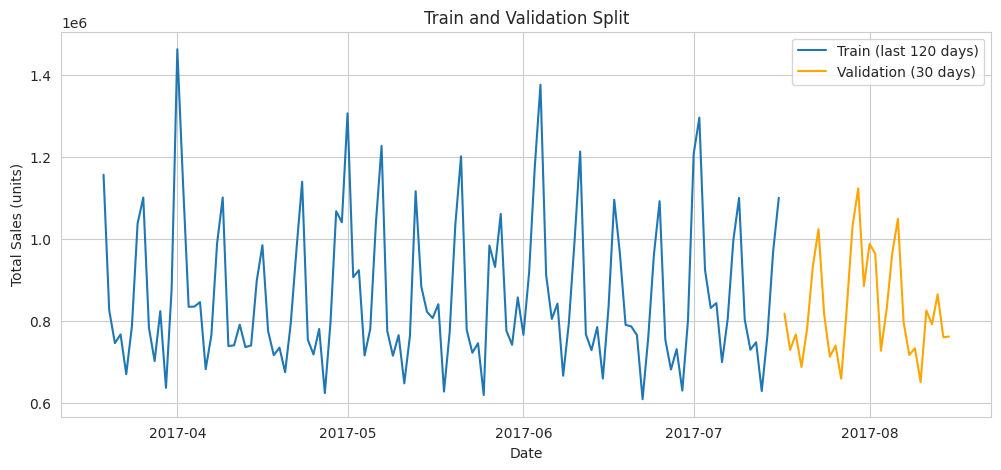

In [ ]:
# Plot the split

plt.figure()
plt.plot(train_df['date'].tail(120), train_df['sales'].tail(120), label='Train (last 120 days)')
plt.plot(valid_df['date'], valid_df['sales'], color='orange', label='Validation (30 days)')
plt.title('Train and Validation Split')
plt.xlabel('Date')
plt.ylabel('Total Sales (units)')
plt.legend()
plt.show()

# 9. Baseline Forecast

## **Model 1: Naive Forecast**

The **Naive Forecast** repeats the last training value for every validation day.
It is the simplest possible model. Every other model must beat it to be worth using.

**Define the metrics**

We define the metrics once and reuse them for all models.

In [ ]:
def evaluate(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    wape = np.sum(np.abs(actual - predicted)) / np.sum(actual) * 100
    return mae, rmse, wape

# Store the actual validation values
actual = valid_df['sales'].values
print('Total actual validation sales:', actual.sum())

Total actual validation sales: 24985326.8026398


WAPE divides by total actual sales. The total is above zero, so the metric is valid.

**Naive forecast**

In [ ]:
last_value = train_df['sales'].iloc[-1]
naive_pred = np.full(horizon, last_value)

print('Last training date:', train_df['date'].iloc[-1].date())
print('Last training value:', round(last_value))

mae, rmse, wape = evaluate(actual, naive_pred)
print(f'Naive  MAE: {mae:,.0f} | RMSE: {rmse:,.0f} | WAPE: {wape:.1f}%')

Last training date: 2017-07-16
Last training value: 1100804
Naive  MAE: 269,489 | RMSE: 294,761 | WAPE: 32.4%


In [ ]:
# Start the results table

results = []
results.append({'Model': 'Naive', 'MAE': mae, 'RMSE': rmse, 'WAPE (%)': wape})

# Keep predictions for the final plot
predictions = {'Naive': naive_pred}

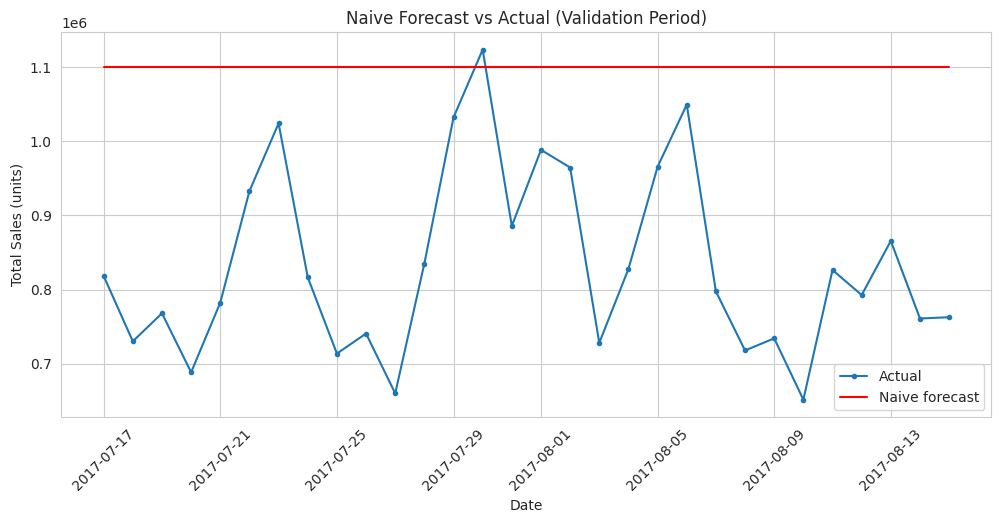

In [ ]:
# Plot naive vs actual

plt.figure()
plt.plot(valid_df['date'], actual, marker='o', markersize=3, label='Actual')
plt.plot(valid_df['date'], naive_pred, color='red', label='Naive forecast')
plt.title('Naive Forecast vs Actual (Validation Period)')
plt.xlabel('Date')
plt.ylabel('Total Sales (units)')
plt.xticks(rotation=45)
plt.legend()
plt.show()

### What we did

- We held out the last 30 days for validation and trained on everything before.
- We built the Naive Forecast, which gives a flat line.
- A flat line cannot follow the weekly pattern, so we expect a large error.
- We write the interpretation after we see the metrics.

### Outputs

1. Split is correct. The naive forecast uses 2017-07-16 as the last training date, so validation starts on 2017-07-17. I did not see the split sizes or the overlap check, but the plot and dates are consistent with a clean split.
2. Naive baseline: MAE 269,489, RMSE 294,761, WAPE 32.4%.
3. Why the error is large. The last training day was a Sunday, which is the highest weekday (about 1.10M). The naive model repeats this peak on all 30 days. Actual sales average about 833,000 (24,985,327 divided by 30), so the forecast sits too high almost every day.
4. Takeaway. The naive error depends heavily on which weekday the training data ends. This baseline is weak, so beating it is easy. The Seasonal Naive model is the more meaningful baseline.

# Forecasting Models

We build 4 more models. Each one forecasts all 30 validation days using only training data.

1. **Seasonal Naive:** repeat the last 7 training days. This copies the weekly pattern.
2. **Moving Average:** forecast the mean of the last 7 training days. This gives one flat level.
3. **Linear Regression:** use time index and weekday dummies. The model learns a trend and a weekly pattern.
4. **Exponential Smoothing (Holt-Winters):** learn a level, a trend, and a weekly pattern. Recent days get more weight.

## **Model 2: Seasonal Naive**

The weekly pattern is strong, so we copy the last 7 training days and repeat them.
Each validation day gets the value from the same weekday in the last training week.

In [ ]:
last_week = train_df['sales'].tail(7).values

# Repeat the last week until we have 30 values, then cut to 30
repeats = int(np.ceil(horizon / 7))
seasonal_pred = np.tile(last_week, repeats)[:horizon]

# Check the alignment: the weekdays must match
print('Last training week weekdays:', train_df['weekday'].tail(7).tolist())
print('First 7 validation weekdays:', valid_df['weekday'].head(7).tolist())

Last training week weekdays: [0, 1, 2, 3, 4, 5, 6]
First 7 validation weekdays: [0, 1, 2, 3, 4, 5, 6]


The last training week ends on Sunday (6) and the validation period starts on Monday (0). The tiled values start with the Monday of the last training week, so they line up with the validation weekdays. The two printed lists should show the same set of weekdays in the same order, which confirms this.

In [ ]:
mae, rmse, wape = evaluate(actual, seasonal_pred)
print(f'Seasonal Naive  MAE: {mae:,.0f} | RMSE: {rmse:,.0f} | WAPE: {wape:.1f}%')

results.append({'Model': 'Seasonal Naive', 'MAE': mae, 'RMSE': rmse, 'WAPE (%)': wape})
predictions['Seasonal Naive'] = seasonal_pred

Seasonal Naive  MAE: 60,672 | RMSE: 91,696 | WAPE: 7.3%


## **Model 3: Moving Average (7 days)**

We average the last 7 training days and use that one value for all 30 days.
A 7-day window covers every weekday once, so the weekly pattern cancels out.
A longer window reacts slowly to change. A shorter window reacts fast but copies noise.
This model has no weekly shape, so we expect it to miss the weekend peaks.

In [ ]:
window = 7
ma_value = train_df['sales'].iloc[-window:].mean()
ma_pred = np.full(horizon, ma_value)

mae, rmse, wape = evaluate(actual, ma_pred)
print(f'Moving Average  MAE: {mae:,.0f} | RMSE: {rmse:,.0f} | WAPE: {wape:.1f}%')

results.append({'Model': 'Moving Average (7)', 'MAE': mae, 'RMSE': rmse, 'WAPE (%)': wape})
predictions['Moving Average (7)'] = ma_pred

Moving Average  MAE: 98,151 | RMSE: 123,357 | WAPE: 11.8%


## **Model 4: Linear Regression**

The model learns one number for each feature:
- `time_index` gives the trend (sales rise over time).
- Weekday dummies give the weekly pattern (Sunday is high, Thursday is low).

We use only features known in advance, so we do not use future sales.
We skip `onpromotion` because we do not know future promotions at forecast time.
We also train on the most recent 365 days only. The trend changed over the years,
so old data would pull the straight line away from the current level.

Build features

In [ ]:
def make_features(df):
    X = pd.get_dummies(df['weekday'], prefix='wd', drop_first=True).astype(int)
    X['time_index'] = df['time_index'].values
    return X

train_recent = train_df.tail(365)

X_train = make_features(train_recent)
y_train = train_recent['sales']

X_valid = make_features(valid_df)
X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)

print(X_train.shape, X_valid.shape)
print(list(X_train.columns))

(365, 7) (30, 7)
['wd_1', 'wd_2', 'wd_3', 'wd_4', 'wd_5', 'wd_6', 'time_index']


Fit and predict

In [ ]:
lr = LinearRegression()
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_valid)

print('Daily trend (units per day):', round(lr.coef_[-1]))

mae, rmse, wape = evaluate(actual, lr_pred)
print(f'Linear Regression  MAE: {mae:,.0f} | RMSE: {rmse:,.0f} | WAPE: {wape:.1f}%')

results.append({'Model': 'Linear Regression', 'MAE': mae, 'RMSE': rmse, 'WAPE (%)': wape})
predictions['Linear Regression'] = lr_pred

Daily trend (units per day): 390
Linear Regression  MAE: 92,052 | RMSE: 112,111 | WAPE: 11.1%


Check negative predictions

In [ ]:
print('Negative predictions:', (lr_pred < 0).sum())
print('Lowest prediction:', round(lr_pred.min()))

Negative predictions: 0
Lowest prediction: 732772


## **Model 5: Exponential Smoothing (Holt-Winters)**

This model keeps three parts and updates them each day, giving more weight to recent days:
- **Level:** the current sales level.
- **Trend:** the direction of change.
- **Seasonality:** the repeating weekly pattern (period = 7).

We use the same last 365 days as the Linear Regression model.

In [ ]:
hw_train = train_recent.set_index('date')['sales']
hw_train.index.freq = 'D'

hw_model = ExponentialSmoothing(
    hw_train,
    trend='add',
    seasonal='add',
    seasonal_periods=7
).fit()

hw_pred = hw_model.forecast(horizon).values

mae, rmse, wape = evaluate(actual, hw_pred)
print(f'Exponential Smoothing  MAE: {mae:,.0f} | RMSE: {rmse:,.0f} | WAPE: {wape:.1f}%')

results.append({'Model': 'Exponential Smoothing', 'MAE': mae, 'RMSE': rmse, 'WAPE (%)': wape})
predictions['Exponential Smoothing'] = hw_pred

Exponential Smoothing  MAE: 58,380 | RMSE: 88,832 | WAPE: 7.0%


### Check the forecast dates line up

In [ ]:
print('Forecast starts after:', hw_train.index[-1].date())
print('Validation starts on:', valid_df['date'].iloc[0].date())
print('Negative predictions:', (hw_pred < 0).sum())

Forecast starts after: 2017-07-16
Validation starts on: 2017-07-17
Negative predictions: 0


### Quick look at the results so far

In [ ]:
pd.DataFrame(results).round(1)

,Model,MAE,RMSE,WAPE (%)
0,Naive,269489.4,294761.2,32.4
1,Seasonal Naive,60671.6,91695.5,7.3
2,Moving Average (7),98150.8,123357.5,11.8
3,Linear Regression,92052.0,112111.5,11.1
4,Exponential Smoothing,58380.2,88832.5,7.0


### What we did

- Seasonal Naive copies the last full week.
- Moving Average uses one flat level from the last 7 days.
- Linear Regression learns a straight-line trend plus weekday effects.
- Holt-Winters learns a level, trend, and weekly pattern that adapt to recent data.

## Outputs

1. Alignment is correct. The weekday lists match, and the Holt-Winters forecast starts on 2017-07-17, the day after training ends. No negative predictions appeared, and you reported no convergence warning.

2. All three metrics give the same ranking.

| Rank | Model                 | MAE     | RMSE    | WAPE  |
| ---- | --------------------- | ------- | ------- | ----- |
| 1    | Exponential Smoothing | 58,380  | 88,832  | 7.0%  |
| 2    | Seasonal Naive        | 60,672  | 91,696  | 7.3%  |
| 3    | Linear Regression     | 92,052  | 112,111 | 11.1% |
| 4    | Moving Average (7d)   | 98,151  | 123,357 | 11.8% |
| 5    | Naive                 | 269,489 | 294,761 | 32.4% |

3. Every model beats the Naive baseline. Exponential Smoothing has an MAE about 78% lower than Naive.

4. The top gap is small. Exponential Smoothing beats Seasonal Naive by only 3.8% on MAE. The validation period has only 30 days, so we cannot call this a strong win.

5. The business meaning. Average actual sales were about 833,000 units per day (24.99M divided by 30). A 7.0% WAPE means the best model misses by about 58,000 units on a typical day.

6. Clipping is not needed. No model produced a negative prediction, so clipping at zero changes nothing.

# 11. Model Evaluation and Comparison

Lower error is better. We compare every model with the Naive baseline on the same 30 validation days.

- **MAE:** the average miss in units per day.
- **RMSE:** like MAE, but large misses count more.
- **WAPE:** total absolute error as a percentage of total actual sales.
- **Bias:** the average of (predicted minus actual). A positive value means the model forecasts too high.

**Build the comparison table**

In [ ]:
pd.options.display.float_format = '{:,.1f}'.format

results_df = pd.DataFrame(results)

# Bias: positive means the model forecasts too high on average
bias = {name: (pred - actual).mean() for name, pred in predictions.items()}
results_df['Bias'] = results_df['Model'].map(bias)

# How much lower is each model's MAE than the Naive baseline?
naive_mae = results_df.loc[results_df['Model'] == 'Naive', 'MAE'].iloc[0]
results_df['MAE vs Naive (%)'] = (1 - results_df['MAE'] / naive_mae) * 100

results_df = results_df.sort_values('MAE').reset_index(drop=True)
results_df

,Model,MAE,RMSE,WAPE (%),Bias,MAE vs Naive (%)
0,Exponential Smoothing,"58,380.2","88,832.5",7.0,"6,054.6",78.3
1,Seasonal Naive,"60,671.6","91,695.5",7.3,"-15,219.0",77.5
2,Linear Regression,"92,052.0","112,111.5",11.1,"73,843.8",65.8
3,Moving Average (7),"98,150.8","123,357.5",11.8,"-11,627.7",63.6
4,Naive,"269,489.4","294,761.2",32.4,"267,959.5",0.0


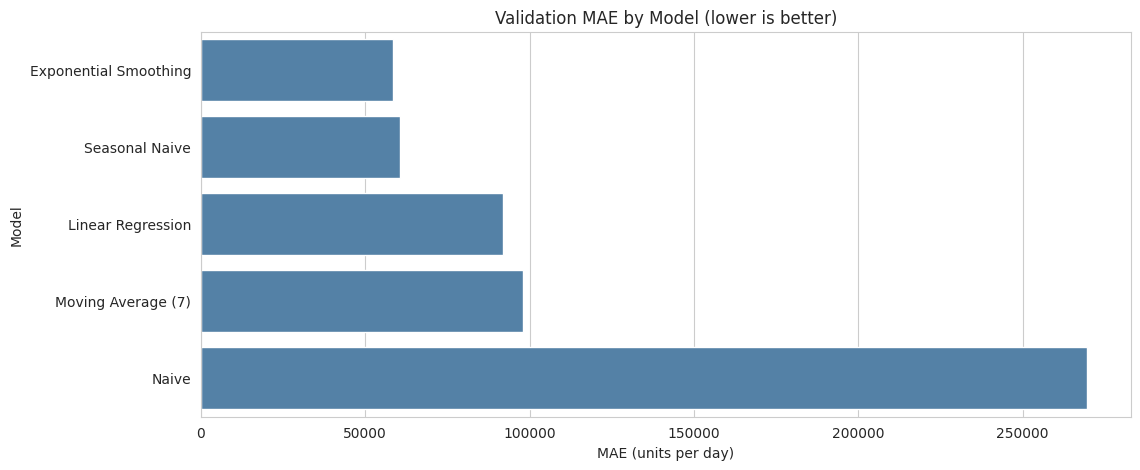

In [ ]:
# Chart the MAE

plt.figure()
sns.barplot(data=results_df, x='MAE', y='Model', color='steelblue')
plt.title('Validation MAE by Model (lower is better)')
plt.xlabel('MAE (units per day)')
plt.ylabel('Model')
plt.show()

In [ ]:
# Size of the gap between the top two models

best = results_df.loc[0]
second = results_df.loc[1]
gap = (second['MAE'] - best['MAE']) / second['MAE'] * 100

print('Best model:', best['Model'])
print('Second model:', second['Model'])
print(f'Best model MAE is {gap:.1f}% lower than the second model.')

Best model: Exponential Smoothing
Second model: Seasonal Naive
Best model MAE is 3.8% lower than the second model.


### Findings

- All four models beat the Naive baseline (MAE 269,489).
- Exponential Smoothing has the lowest error on MAE, RMSE, and WAPE (58,380 | 88,832 | 7.0%).
- Seasonal Naive is a close second (60,672 | 91,696 | 7.3%). Its MAE is only 3.8% higher.
- Linear Regression (92,052) and Moving Average (98,151) are clearly weaker.
- No model produced negative predictions, so clipping at zero was not needed.
- We add the bias finding after we see the table.

# 12. Actual vs. Predicted Sales

We plot the forecasts to see whether they capture the weekly pattern.

Numbers alone can hide problems such as a wrong level or missed weekend peaks.

**Best Model: Exponential Smoothing - Holt-Winters**

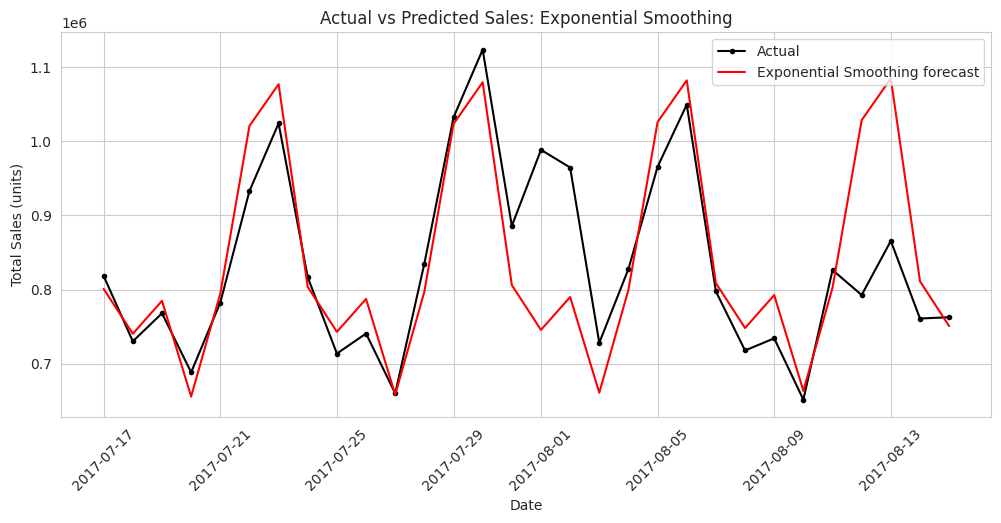

In [ ]:
# Best model against actual sales

best_name = results_df.loc[0, 'Model']

plt.figure()
plt.plot(valid_df['date'], actual, marker='o', markersize=3, color='black', label='Actual')
plt.plot(valid_df['date'], predictions[best_name], color='red', label=f'{best_name} forecast')
plt.title(f'Actual vs Predicted Sales: {best_name}')
plt.xlabel('Date')
plt.ylabel('Total Sales (units)')
plt.xticks(rotation=45)
plt.legend()
plt.show()

**All models together**

We leave out the Naive model. Its flat line at 1.10M would squash the chart.

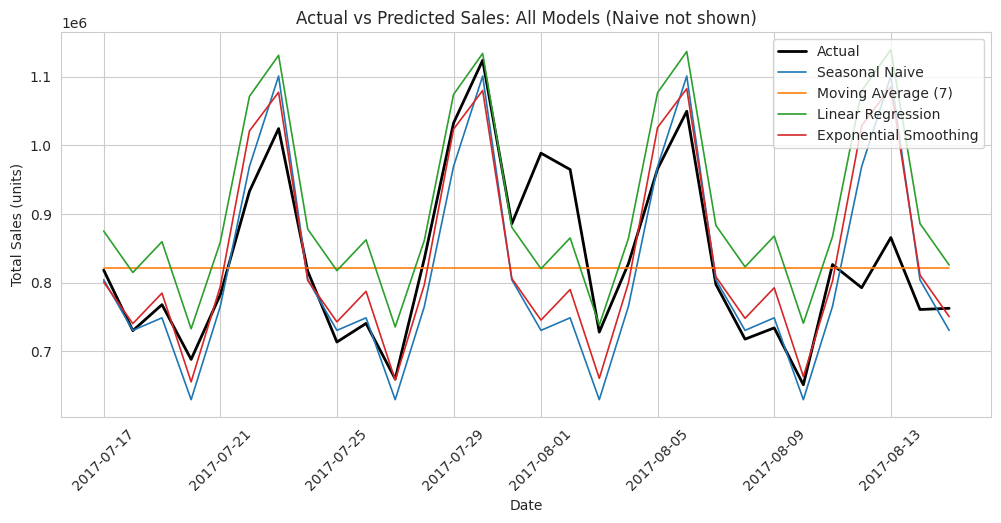

In [ ]:
plt.figure()
plt.plot(valid_df['date'], actual, color='black', linewidth=2, label='Actual')

for name, pred in predictions.items():
    if name != 'Naive':
        plt.plot(valid_df['date'], pred, linewidth=1.2, label=name)

plt.title('Actual vs Predicted Sales: All Models (Naive not shown)')
plt.xlabel('Date')
plt.ylabel('Total Sales (units)')
plt.xticks(rotation=45)
plt.legend()
plt.show()

### What we check in the plots

- Do the forecasts rise on weekends and fall midweek?
- Is the overall level close to the actual line?
- Which models miss the peaks, and which models sit too high or too low?

### Findings from the table and plots

- Exponential Smoothing has the lowest error on all three metrics and a small bias (+6,055 units per day).
- Seasonal Naive is close behind. The MAE gap is only 3.8%.
- Linear Regression follows the weekly shape but forecasts too high (bias +73,844). A level error, not a shape error, causes its weaker score.
- Moving Average is a flat line, so it cannot capture the weekly pattern.
- Exponential Smoothing misses the early August peak (2017-07-31 to 2017-08-02) and over-predicts the weekend of 2017-08-12 to 2017-08-13.

# 13. Final Model Selection

## Selected model: **Exponential Smoothing (Holt-Winters)**

We selected it because it has the lowest validation error on all three metrics:
MAE 58,380, RMSE 88,832, and WAPE 7.0%.

## Why it works
- It captures the weekly pattern with a 7-day seasonal component.
- It updates its level from recent data, so it matches the current sales level (bias +6,055).
- It needs no future inputs, so it is realistic to use.

## How strong is this result?
The model beats Naive by 78.3%. That is a clear win.
The model beats Seasonal Naive by only 3.8%. That is a small gap on a 30-day validation window.
We cannot say Exponential Smoothing is clearly better than Seasonal Naive.
If simplicity matters more, Seasonal Naive is a reasonable alternative.

## Business meaning
Average actual sales were about 833,000 units per day.
The selected model misses by about 58,000 units on a typical day (7.0%).

**Final summary numbers**

In [ ]:
avg_daily = actual.mean()
best_mae = results_df.loc[0, 'MAE']

print(f'Average actual daily sales: {avg_daily:,.0f}')
print(f'Best model MAE: {best_mae:,.0f}')
print(f'MAE as % of average daily sales: {best_mae / avg_daily * 100:.1f}%')

Average actual daily sales: 832,844
Best model MAE: 58,380
MAE as % of average daily sales: 7.0%


# 14. Conclusion and Limitations

## Summary
1. We forecast **total daily sales** across all stores and product families.
2. The EDA showed a strong upward trend, a strong weekly pattern (Sunday highest, Thursday lowest), and a December peak.
3. We split the data by time. The last 30 days (2017-07-17 to 2017-08-15) were the validation period.
4. We compared 5 models. All beat the Naive baseline.
5. **Exponential Smoothing was best:** MAE 58,380 | RMSE 88,832 | WAPE 7.0%.
6. Seasonal Naive was very close (MAE 60,672), so a simple weekly repeat is already strong for this series.

## Limitations
1. **Scope.** The models forecast total sales only, not each store or product family.
2. **Short validation window.** 30 days is only 4 weeks. The gap between the top two models is small and could change on another window.
3. **No holidays or paydays.** The model misses the early August peak, which may relate to the turn of the month. We did not test this.
4. **Promotions and oil were not used.** We do not know future promotions at forecast time. Oil trends over time in the same way as sales, so it is not a reliable signal.
5. **Unexplained level shifts.** The sales level jumped in 2014 and early 2015. We ruled out store coverage, but we did not find the cause.
6. **Filled Christmas days.** Four closed days were filled by interpolation. Real sales were zero on those days.
7. **Linear Regression window.** We used only the last 365 days. The poor level fit was not tested with other windows.
8. **One validation period.** Validation covers July and August only, so we did not test how the models handle December or January 1.

## Recommendations
1. Add holiday and payday features.
2. Test several validation windows (rolling-origin evaluation).
3. Forecast by store or product family.
4. Try a shorter training window for Linear Regression.